In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import tplquad
from scipy.special import spherical_jn

# Double Folding model

$$ {\underline{\fbox{ $U_D = \int d^3 \vec{r_1} \int d^3\vec{r_2} \rho_T(\vec{r_2}) v_d(\rho, E, s) \rho_p(\vec{r_1})$}}}$$

### $ U_D(R) $ Direct Part of $ {}^{16}\mathrm{O} + {}^{16}\mathrm{O} $

$$U_D(R) = \int^\infty _0 \int^\infty _0 \int^\infty _0 \underbrace{k^2 j_0(kR) v_D(k) F(\rho) g(E)}_{I_{V_D}} \:\: \underbrace{ r_1^2 j_0(kr_1) \rho_p(r_1) }_{I_p} \:\: \underbrace{ r_2^2 j_0(kr_2) \rho_t(r_2)}_{I_T} dk dr_1 dr_2$$

### Potenial

$$V_D(s,\rho, E) = \bigg[11061.625 \frac{e^{-4s}}{4s} - 2537.5 \frac{e^{-2.5s}}{2.5s}\bigg]F(\rho)g(E) \\ \\ {\sf{where,}} \\ F(\rho) = c\bigg(1+\alpha\exp(- \beta \rho) -\gamma \rho \bigg) \\ g(E) = \bigg(1-0.003 E_{AP} \bigg) \\ \sf{For\:\: CDM3Y1},C = 0.3429,\:\: \alpha = 3.0232 \:\: \& \:\: \beta = 3.5512 fm^3 \:\: \gamma = 0.5$$

In [2]:
def integrate(k, r2, r1,
              R,
              c1=11061.625,
              c2=2537.5,
              c=0.3429,
              mu1=4,
              mu2=2.5,
              alpha=3.0232,
              beta=3.5512,
              gamma=0.5):

    # Density functions
#     projectile
    def density_p(r, rho_0=0.181, a=0.45, R_0=2.525):
        return rho_0/(1+np.exp((r-R_0)/a))

#     target
    def density_t(r, rho_0=0.181, a=0.45, R_0=2.525):
        return rho_0/(1+np.exp((r-R_0)/a))


    # g(E)
    def g(E_lab, A=32):
        return (1-0.003*E_lab/A)

    # Total density
    rho = density_p(r1) + density_t(r2)

    # Fourier transform of M3Y interaction
    vD = (
        (4*np.pi*c1/mu1) / (mu1**2 + k**2)
        -
        (4*np.pi*c2/mu2) / (mu2**2 + k**2)
    )

    # Density-dependent factor
    F = c * (1 + alpha * np.exp(-beta*rho) - gamma * rho)

    return 8*(
        k**2
        * spherical_jn(0, k*R)
        * vD
        * F
        * g(E_lab=145)
        * r1**2
        * r2**2
        * spherical_jn(0, k*r1)
        * spherical_jn(0, k*r2)
        * density_p(r1)
        * density_t(r2)
    )

In [3]:
R_vals = np.array([0.5*i for i in range(17)])

In [4]:
datas = []
errors = []

In [5]:
for i in range(0,17):

    result, error = tplquad(
        integrate,

        # r1: outer integral
        0, 5,

        # r2: middle integral
        lambda r1: 0,
        lambda r1: 8,

        # k: inner integral
        lambda r1, r2: 0,
        lambda r1, r2: 4,

        args=(R_vals[i],)
    )

    datas.append(result)
    errors.append(error)

In [6]:
len(datas)

17

In [7]:
R = np.linspace(0,8,17)

In [8]:
datas

[251.80676738274383,
 243.91142636964307,
 222.23071887266994,
 191.54632146362218,
 156.95367797579615,
 122.26906332498612,
 89.89867211934961,
 61.350264344749974,
 37.66207115078108,
 19.563507749560188,
 7.330513820061421,
 0.4768048251121302,
 -2.298215959321075,
 -2.6674660102874825,
 -2.0506606538413337,
 -1.2851213939098947,
 -0.6982798092264456]

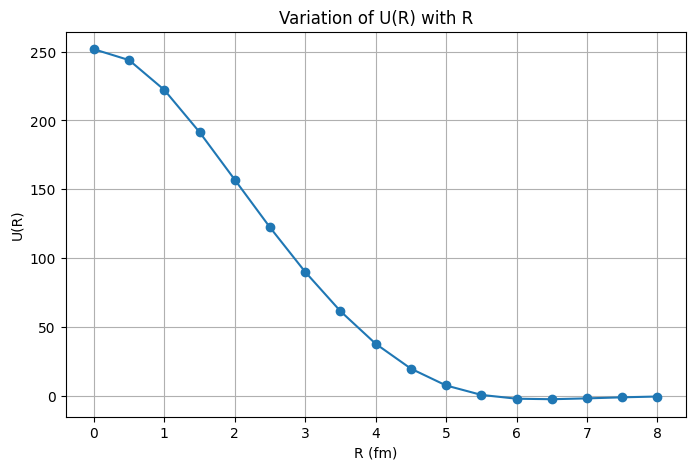

In [9]:
R_vals = np.array([0.5*i for i in range(17)])

plt.figure(figsize=(8, 5))

plt.plot(R_vals, datas, marker='o')

plt.xlabel('R (fm)')
plt.ylabel('U(R)')
plt.title('Variation of U(R) with R')

plt.grid(True)
plt.show()